# Etapa 6 — VAR e decomposição da variância (FEVD)

O mini-VAR, agora com as 7 variáveis.

**Ordenação de Cholesky** (quem vem antes fica com a sobreposição):

`Treasury → VIX → dólar AFE` (externas) `→ Selic → primário → CDS` (domésticas) `→ câmbio`

**Defasagens:** BIC, conferindo autocorrelação dos resíduos (teste Portmanteau).

**Pergunta final:** do erro de previsão do câmbio em h = 1, 3, 6 e 12 meses, quanto vem de
choques externos, quanto de domésticos e quanto do choque próprio do câmbio?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.api import VAR

dados = pd.read_csv("dados/tratados/variacoes_mensais.csv", index_col=0, parse_dates=True).asfreq("ME")

EXTERNAS = ["d_ust10", "dl_vix", "dl_dolar"]
DOMESTICAS = ["d_selic", "d_primario", "dl_cds"]
ORDEM = EXTERNAS + DOMESTICAS + ["dl_cambio"]
HORIZONTES = [1, 3, 6, 12]

df = dados[ORDEM]   # a ordem das colunas É a ordem de Cholesky

## 1. Escolha das defasagens

Estimamos VARs com p = 0…6 e comparamos critérios de informação (menor = melhor).
O asterisco marca o mínimo de cada critério.

In [2]:
selecao = VAR(df).select_order(maxlags=6)
print(selecao.summary())
print("Escolhas:", selecao.selected_orders)

 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0       7.422      7.534*       1672.      7.467*
1      7.110*       8.009      1225.*       7.473
2       7.112       8.797       1229.       7.794
3       7.196       9.667       1341.       8.195
4       7.295       10.55       1492.       8.612
5       7.528       11.57       1906.       9.163
6       7.676       12.51       2248.       9.629
-------------------------------------------------
Escolhas: {'aic': np.int64(1), 'bic': np.int64(0), 'hqic': np.int64(0), 'fpe': np.int64(1)}


**Checagem dos resíduos (Portmanteau):** H₀ = resíduos sem autocorrelação até 12 defasagens.
Se rejeitar (p < 0,05), o VAR deixou dinâmica de fora → acrescentamos uma defasagem e testamos de novo.

Obs.: se o BIC escolher p = 0 (nenhuma defasagem), usamos p = 1 — um VAR sem passado não é um VAR.

In [3]:
p = max(1, selecao.bic)
while True:
    var = VAR(df).fit(p)
    teste = var.test_whiteness(nlags=12)
    print(f"p = {p}:  Portmanteau p-valor = {teste.pvalue:.3f}")
    if teste.pvalue >= 0.05 or p >= 6:
        break
    p += 1

print(f"\nDefasagens escolhidas: p = {p}")
print("VAR estável (todas as raízes dentro do círculo unitário)?", var.is_stable())

p = 1:  Portmanteau p-valor = 0.256

Defasagens escolhidas: p = 1
VAR estável (todas as raízes dentro do círculo unitário)? True


## 2. O Brasil "afeta o mundo" com atraso? (teste de Granger)

Num VAR padrão, as defasagens das domésticas entram nas equações das externas. Se a hipótese de
economia pequena vale, elas **não deveriam** ajudar a prever as externas.

H₀: as defasagens do bloco doméstico (incluindo o câmbio) **não** ajudam a prever o bloco externo.

In [4]:
granger = var.test_causality(caused=EXTERNAS, causing=DOMESTICAS + ["dl_cambio"], kind="f")
print(granger.summary())

Granger causality F-test. H_0: ['d_selic', 'd_primario', 'dl_cds', 'dl_cambio'] do not Granger-cause [d_ust10, dl_vix, dl_dolar]. Conclusion: fail to reject H_0 at 5% significance level.
Test statistic Critical value p-value     df    
------------------------------------------------
         1.364          1.759   0.176 (12, 1435)
------------------------------------------------


## 3. FEVD do câmbio

`fevd.decomp[variável, horizonte, choque]`. Cada linha soma 1 (100% do erro de previsão).

In [5]:
fevd = var.fevd(12)
i_cambio = ORDEM.index("dl_cambio")

fevd_cambio = pd.DataFrame(
    fevd.decomp[i_cambio],
    index=[f"h={h}" for h in range(1, 13)],
    columns=ORDEM,
)
fevd_cambio.loc[[f"h={h}" for h in HORIZONTES]].round(3)

,d_ust10,dl_vix,dl_dolar,d_selic,d_primario,dl_cds,dl_cambio
h=1,0.006,0.094,0.286,0.002,0.011,0.209,0.392
h=3,0.006,0.094,0.284,0.003,0.011,0.209,0.392
h=6,0.006,0.094,0.284,0.004,0.011,0.209,0.392
h=12,0.006,0.094,0.284,0.004,0.011,0.209,0.392


### Agregando por bloco

- **Externo** = soma dos choques de Treasury, VIX e dólar
- **Doméstico** = soma dos choques de Selic, primário e CDS
- **Próprio** = choque do câmbio que nenhuma outra variável explica (≈ o "não explicado" da regressão)

A última coluna compara com a etapa 5: peso externo **dentro do que é explicado** (ext / (ext + dom)).

In [6]:
blocos = pd.DataFrame({
    "externo": fevd_cambio[EXTERNAS].sum(axis=1),
    "doméstico": fevd_cambio[DOMESTICAS].sum(axis=1),
    "próprio do câmbio": fevd_cambio["dl_cambio"],
})
blocos["externo / explicado"] = blocos["externo"] / (blocos["externo"] + blocos["doméstico"])

blocos.loc[[f"h={h}" for h in HORIZONTES]].round(3)

,externo,doméstico,próprio do câmbio,externo / explicado
h=1,0.386,0.222,0.392,0.635
h=3,0.384,0.224,0.392,0.632
h=6,0.384,0.224,0.392,0.632
h=12,0.384,0.224,0.392,0.632


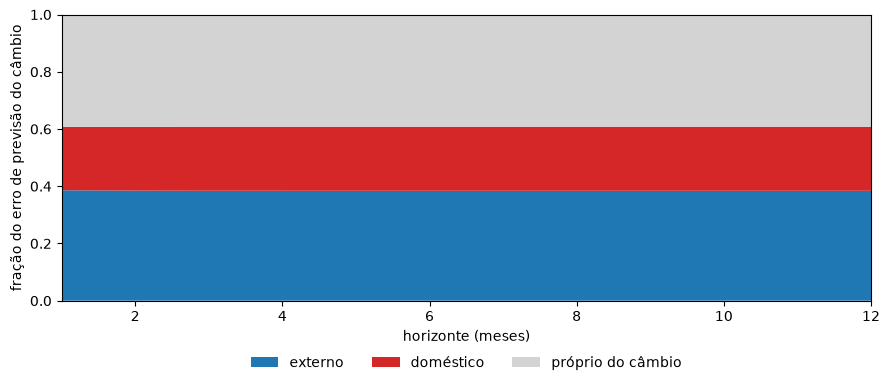

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.stackplot(range(1, 13), blocos["externo"], blocos["doméstico"], blocos["próprio do câmbio"],
             labels=["externo", "doméstico", "próprio do câmbio"],
             colors=["tab:blue", "tab:red", "lightgray"])
ax.set_xlabel("horizonte (meses)")
ax.set_ylabel("fração do erro de previsão do câmbio")
ax.set_xlim(1, 12)
ax.set_ylim(0, 1)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
fig.tight_layout()
plt.show()

## 4. Conferência: a ordem *dentro* dos blocos não muda o total do bloco

Invertemos a ordem interna das externas e das domésticas (câmbio continua por último).

In [8]:
ordem_alt = EXTERNAS[::-1] + DOMESTICAS[::-1] + ["dl_cambio"]
var_alt = VAR(dados[ordem_alt]).fit(p)
dec_alt = pd.DataFrame(var_alt.fevd(12).decomp[-1], columns=ordem_alt)

comparacao = pd.DataFrame({
    "externo (ordem original)": blocos["externo"].values,
    "externo (ordem interna invertida)": dec_alt[EXTERNAS].sum(axis=1).values,
    "doméstico (ordem original)": blocos["doméstico"].values,
    "doméstico (ordem interna invertida)": dec_alt[DOMESTICAS].sum(axis=1).values,
}, index=[f"h={h}" for h in range(1, 13)])
comparacao.loc[[f"h={h}" for h in HORIZONTES]].round(4)

,externo (ordem original),externo (ordem interna invertida),doméstico (ordem original),doméstico (ordem interna invertida)
h=1,0.3860,0.3860,0.2216,0.2216
h=3,0.3841,0.3841,0.2237,0.2237
h=6,0.3841,0.3841,0.2238,0.2238
h=12,0.3841,0.3841,0.2238,0.2238


## 5. Respostas ao impulso acumuladas do câmbio

Efeito acumulado (em % no nível do câmbio) de um choque de 1 desvio-padrão em cada variável,
com intervalo de confiança de 95%. Se o intervalo cruza o zero, o efeito não é significativo.

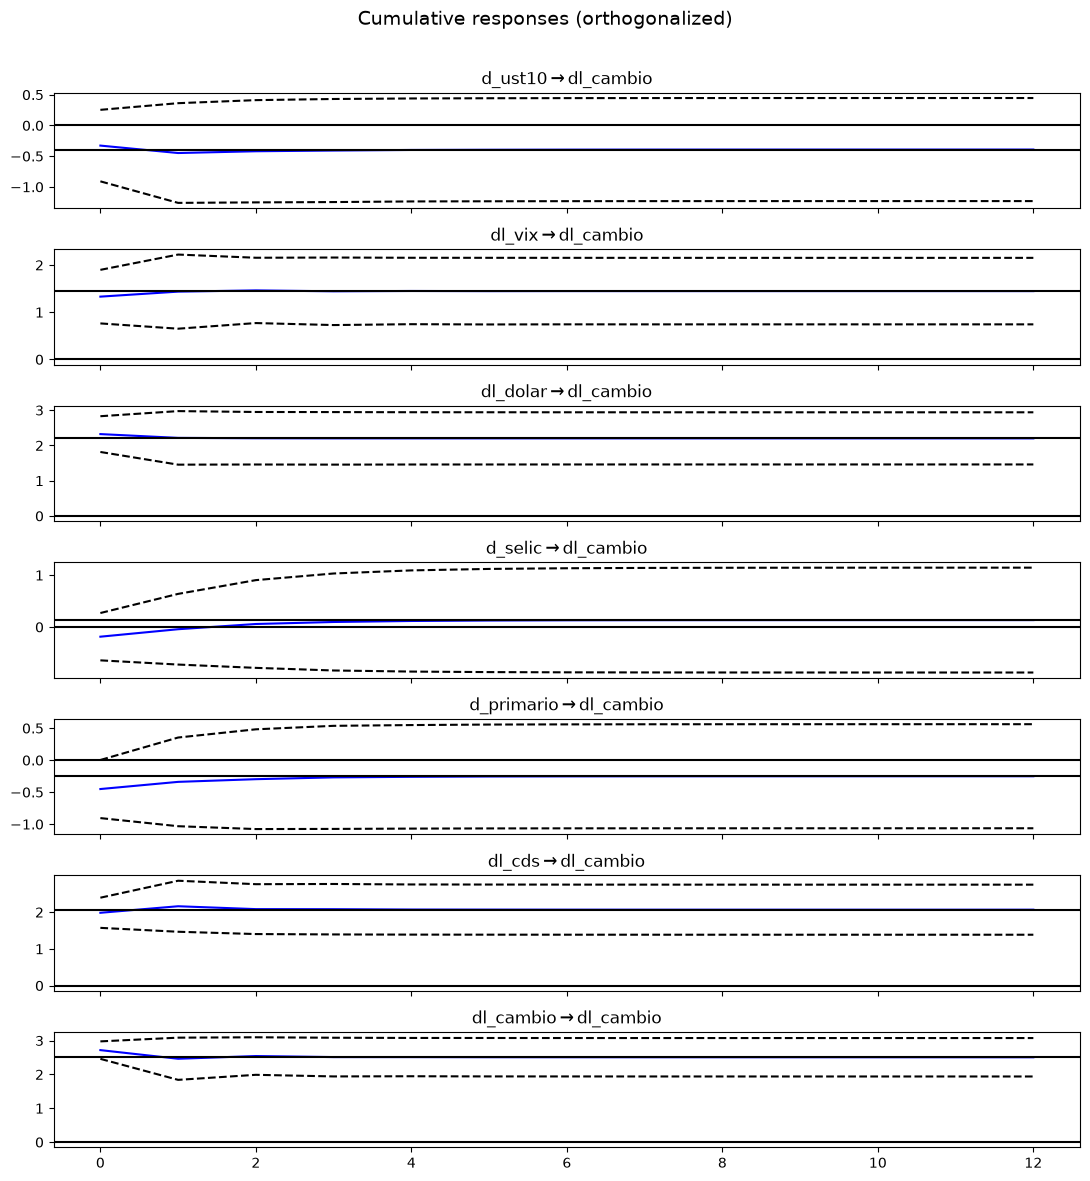

In [9]:
irf = var.irf(12)
fig = irf.plot_cum_effects(orth=True, response="dl_cambio", figsize=(11, 12))
fig.tight_layout(rect=(0, 0, 1, 0.97))   # evita títulos sobrepostos

In [10]:
fevd_cambio.to_csv("resultados/etapa6_fevd_cambio_por_variavel.csv")
blocos.to_csv("resultados/etapa6_fevd_cambio_por_bloco.csv")

## O que conferir

- **p** escolhido e Portmanteau sem rejeição; VAR **estável**.
- **Granger**: não rejeitar H₀ apoia a hipótese de economia pequena.
- **FEVD em h=1** deve ficar próxima da etapa 5 (o VAR em h=1 é a mesma limpeza, agora nas surpresas).
- **h=1 → h=12**: a parte externa cresce? (efeitos que chegam com atraso)
- **Seção 4**: totais por bloco idênticos nas duas ordens internas.